### Bibliotecas Utilizadas

In [27]:
import serial
import csv
import os
import matplotlib.pyplot as plt
import time

### Definições e Funções

In [39]:
# Configurações da porta serial
porta = 'COM3'  
baud_rate = 115200  
timeout = 1 

freq = 100


def check_num(valor):
    try:
        float(valor)
        return True
    except ValueError:
        return False



In [66]:
# Função le e grav CSV
def ler_sinal_serial(CODIGO, tempo):
    """
    Da pra botar uma baita descrição da função aki
    """

    arquivo_csv = f'dados_{CODIGO}.csv'
    amostras = int(freq*tempo)

    espera = 5
    # Tempo para estabilizar
    time.sleep(espera) 
    
    try:
        serial_connection = serial.Serial(porta, baud_rate, timeout=timeout)
    except serial.SerialException as e:
        print(f"Erro ao conectar à porta serial: {e}")
        return

    sinal_coletado = []


    # Lê os dados da porta serial
    print(f"Lendo dados da porta serial... Serão registradas {amostras} amostras válidas.")
    contador = 0
    while contador < amostras:
        try:
            linha = serial_connection.readline().decode('utf-8', errors='ignore').strip()
        except Exception:
            linha = ""  # Fallback em caso de erro na leitura

        if linha and check_num(linha):
            contador += 1
            sinal_coletado.append(float(linha))

    # Fecha a conexão serial
    serial_connection.close()

    # Verifica se dados foram coletados
    if sinal_coletado:
        plt.figure(figsize=(6, 4)) 
        plt.plot(sinal_coletado, label="Sinal", marker='.')
        plt.xlabel('Índice da Amostra')
        plt.ylabel('Valor do Sinal')
        plt.title('Gráfico do Sinal Coletado')
        plt.legend()
        #plt.ylim((0, 3.3)) 
        plt.grid(True)
        plt.show()

        # Solicita confirmação 
        confirmacao = input("A coleta está correta? (s/n): ").strip().lower()
        if confirmacao != 's':
            print("Coleta descartada.")
            return  

        # Solicita o rótulo
        rotulo = input("Digite o Rótulo: ").strip()


        try:
            with open(arquivo_csv, mode='a', newline='') as f:
                writer = csv.writer(f)

                if os.stat(arquivo_csv).st_size == 0:  # Verifica se o arquivo está vazio
                    writer.writerow([rotulo])  

                # Escreve os dados coletados
                for valor in sinal_coletado:
                    writer.writerow([valor]) 

                print(f"Dados salvos no arquivo {arquivo_csv}.")
        except Exception as e:
            print(f"Erro ao salvar no arquivo CSV: {e}")



### Efetua Leitura

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


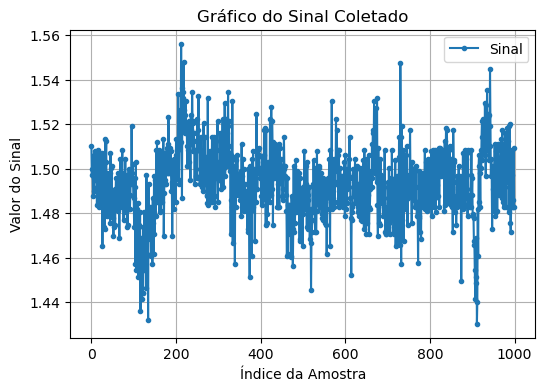

Coleta descartada.


In [86]:
# Exemplo da função
ler_sinal_serial('teste', 10)

## Coleta Sinal Parado

Parado de Olhos Abertos

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


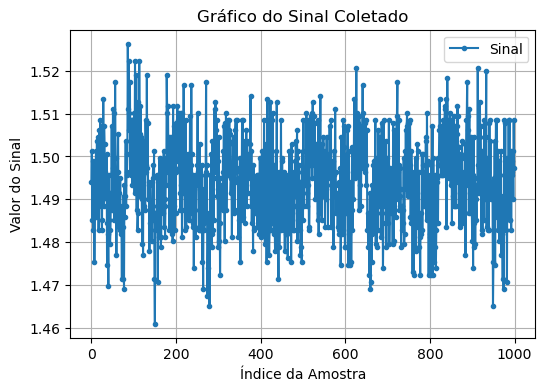

Dados salvos no arquivo dados_olhosabertos.csv.


In [88]:
# Exemplo da função
ler_sinal_serial('olhosabertos', 10)

Parado de Olhos Fechados

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


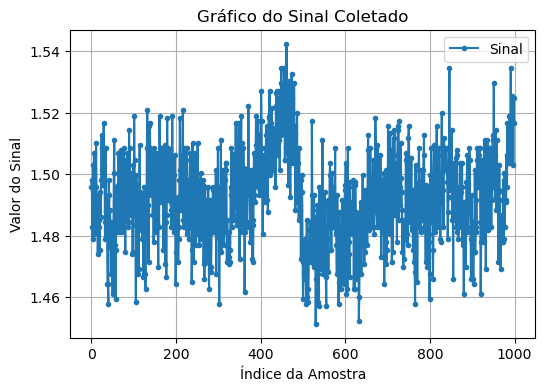

Dados salvos no arquivo dados_olhosfechados.csv.


In [92]:
# Exemplo da função
ler_sinal_serial('olhosfechados', 10)

Parado Piscando

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


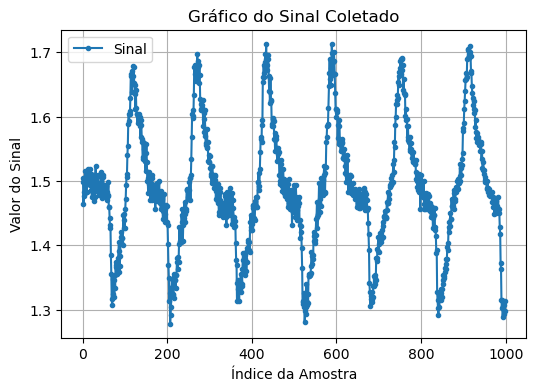

Dados salvos no arquivo dados_olhospisca.csv.


In [ ]:
# Exemplo da função
ler_sinal_serial('olhospisca', 10)

Direita Fecha e Segura

Lendo dados da porta serial... Serão registradas 500 amostras válidas.


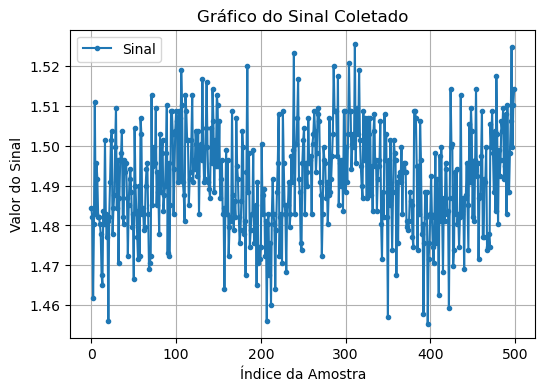

Dados salvos no arquivo dados_direita_01.csv.


In [ ]:
# Exemplo da função
ler_sinal_serial('direita_01', 5)

Direita Fecha e Abre

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


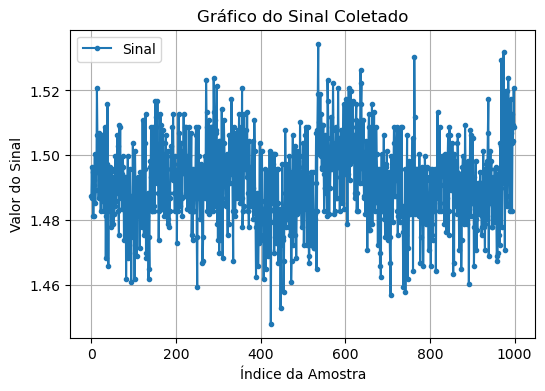

Dados salvos no arquivo dados_direita_02.csv.


In [ ]:
# Exemplo da função
ler_sinal_serial('direita_02', 10)

Esquerda Fecha e segura

Lendo dados da porta serial... Serão registradas 500 amostras válidas.


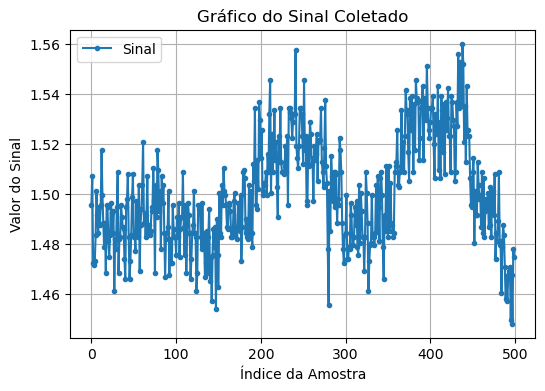

Dados salvos no arquivo dados_esquerda_01.csv.


In [103]:
# Exemplo da função
ler_sinal_serial('esquerda_01', 5)

Esquerda Fecha e Abre

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


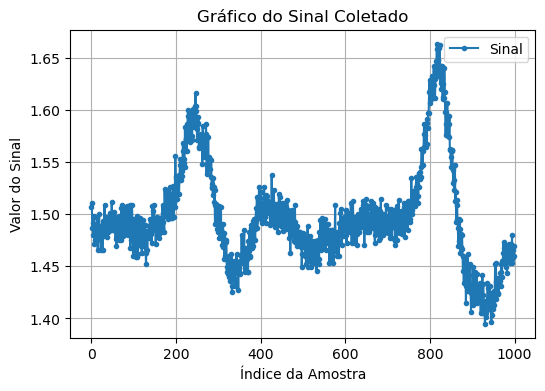

Dados salvos no arquivo dados_esquerda_02.csv.


In [ ]:
# Exemplo da função
ler_sinal_serial('esquerda_02', 10)

Ambas Fecha e segura

Lendo dados da porta serial... Serão registradas 500 amostras válidas.


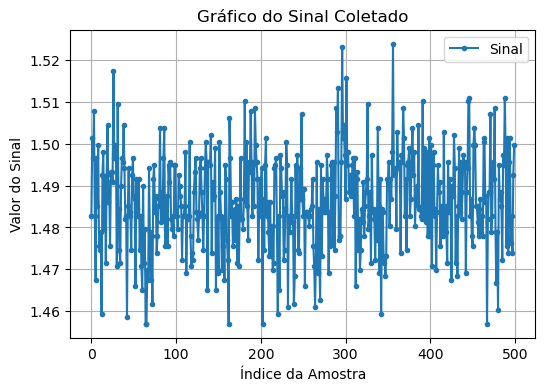

Coleta descartada.


In [ ]:
# Exemplo da função
ler_sinal_serial('frente_01', 5)

Ambas Fecha e abre

Lendo dados da porta serial... Serão registradas 1000 amostras válidas.


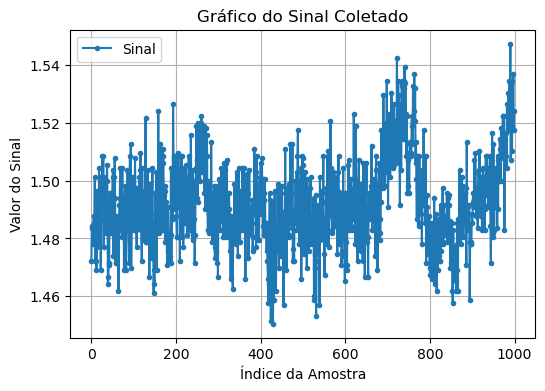

Dados salvos no arquivo dados_frente_02.csv.


In [ ]:
# Exemplo da função
ler_sinal_serial('frente_02', 10)